Load data and get constants

In [1]:
from tttrkit.ptuio.reader import TTTRReader
from tttrkit.ptuio.utils import estimate_tcspc_bins
from tttrkit.ptuio.decoder import T3OverflowCorrector
import numpy as np

from tttrkit.ptuio.reconstructor import ScanConfig
from tttrkit.ptuio.reconstructor import ImageReconstructor


Calculate phasor from TCSPC histogram by numerical integration or by weight-averaging phasor from all pixels



In [2]:
from skimage import io as io

reader = TTTRReader(r"C:\Users\dalibor\Data\FLOPA_dataset\Zeiss_LSM880_HydraHarp400\NADH.ptu")

mask = io.imread(r"C:\Users\dalibor\Data\FLOPA_dataset\Zeiss_LSM880_HydraHarp400\NADH_mask.tif")

wrap = reader.header.tags.get("TTResultFormat_WrapAround", 1024)  # default fallback
repetition_rate = reader.header.tags.get("TTResult_SyncRate",40e6)  
tcspc_resolution = reader.header.tags.get("MeasDesc_Resolution",5e-12)
tcspc_bins = estimate_tcspc_bins(reader.header.tags,buffer=0)
TCSPCresol = reader.header.tags.get("MeasDesc_Resolution")

corrector = T3OverflowCorrector(wraparound=wrap)


cfg = ScanConfig(
    bidirectional=True,
    line_start_marker_delay = int(2.4359999999999997e-05 * repetition_rate),
    line_stop_marker_delay = int(3.0768999999999996e-05 * repetition_rate),
    frames= 1,
    lines=512, 
    pixels=512, 
    line_accumulations= (8,),
    max_detector=1
    )

reconstructor = ImageReconstructor(
        config=cfg, 
        laser_sync_rate=repetition_rate, 
        tcspc_channels= tcspc_bins,
        tcspc_resolution=tcspc_resolution,
        outputs=None,
        roi_mask=mask,
        )

reader.reset()

for chunk in reader.iter_chunks():
    corrected_chunk = corrector.correct(chunk)
    reconstructor.update(corrected_chunk)

result = reconstructor.finalize()
# decay = result.tcspc_histogram.isel(frame=0,sequence=0,channel=0).values

Reconstruction finished.


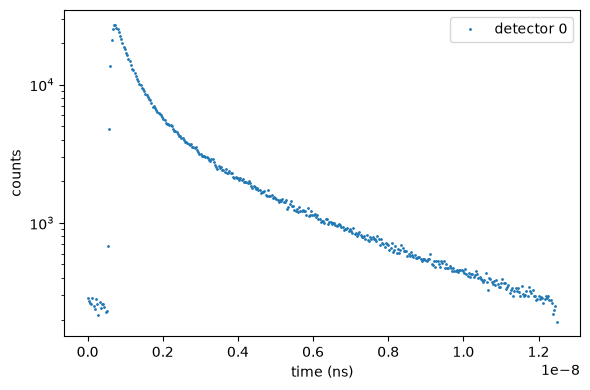

In [3]:
from tttrkit.analysis.visualization import plot_decay, plot_decay_fit

plot_decay(
    dec_list=[
        result.tcspc_histogram.isel(frame=0,sequence=0,channel=0),
              ],
    labels=['detector 0'],
    tm=[result.tcspc_time],

           )

Estimated IRF cut-off: 27


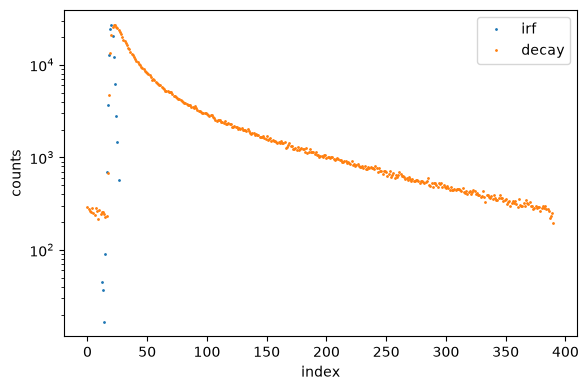

In [4]:
from tttrkit.analysis.decay import fit_decay_reconvolution_folded, birfi, LifetimeParameters

decay = result.tcspc_histogram.isel(frame=0,sequence=0,channel=0,).values

irf = birfi(
    decay=decay,
    smoothing=1,
)

irf[:12] = 0
plot_decay(
    dec_list=[
        irf / max(irf) * max(decay),
        decay,
    ],
    labels = ['irf','decay']
)

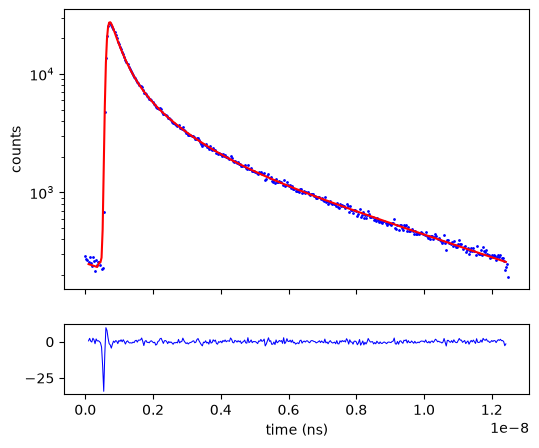

In [5]:

fit_result = fit_decay_reconvolution_folded(
    time_axis=result.tcspc_time.values,
    decay=decay,
    irf=irf,
    fit_limits_channels=(3,len(decay)-2),
    initial_guess=LifetimeParameters(
        amplitudes=[12001,2501, 501],
        taus=[0.5e-9,1.5e-9, 5.1e-9],
        background=2,
        shift=10e-11,
        
    ),
    fixed={'B'}
)

plot_decay_fit(
    tm=result.tcspc_time.values,
    dec=decay,
    fit=fit_result["fit"],
    limits=fit_result["limits"],
    res=fit_result["residuals"],
)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Calibration factor: (0.9475649083678923-0.304194133790597j)


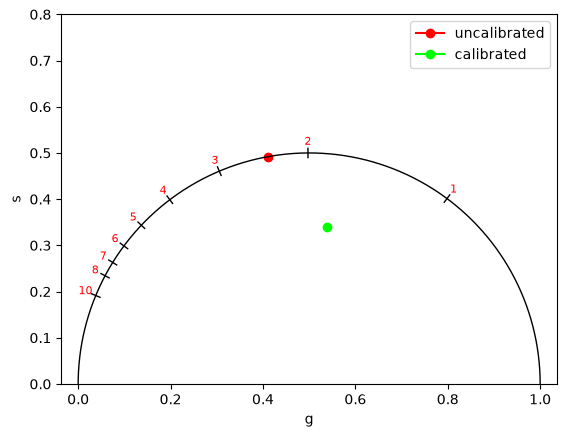

In [6]:
from tttrkit.analysis.phasor import get_phasor_from_decay
import matplotlib.pyplot as plt
from tttrkit.analysis.visualization import draw_unitary_circle


fit_parameters = fit_result["fit_parameters"]
g,s = fit_parameters.theoretical_phasor(frequency=repetition_rate)
phasor_theory = g+s*1j

phasor = get_phasor_from_decay(
    decay=decay,
    tcspc_resolution=tcspc_resolution,
    sync_rate=repetition_rate,

)


calibration_factor = phasor_theory / phasor

calibrated_phasor = phasor * calibration_factor

_,ax = plt.subplots(1,1)
ax.plot(
    phasor.real,
    phasor.imag,
    label='uncalibrated',
    color='red',
    marker='o',

)

ax.plot(
    calibrated_phasor.real,
    calibrated_phasor.imag,
    label='calibrated',
    color='lime',
    marker='o',

)

plt.legend()
draw_unitary_circle(ax=ax,sync_rate=repetition_rate,color='black',tau_max=10,label_color='red')

print(f"Calibration factor: {calibration_factor}")

## Phasor image
Let's check if the phasor image is working correcly

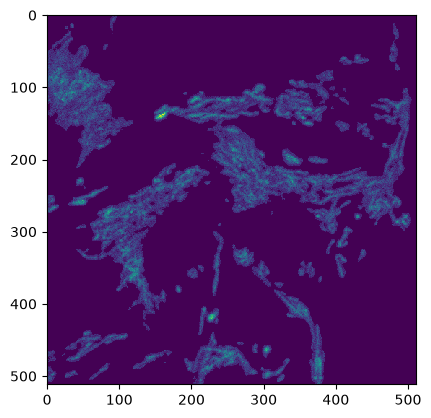

In [14]:
photon_count_image = result.photon_count.isel(frame=0,sequence=0,channel=0).values
fig,ax = plt.subplots(1,1)
ax.imshow(photon_count_image,interpolation="nearest")
plt.show()

In [16]:
g = np.array(
    result.phasor_g.isel(frame=0,sequence=0,channel=0).values,
    dtype=float)
s = np.array(
    result.phasor_s.isel(frame=0,sequence=0,channel=0).values,
    dtype=float)

phasor = (g + 1j * s).astype(complex) * calibration_factor

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


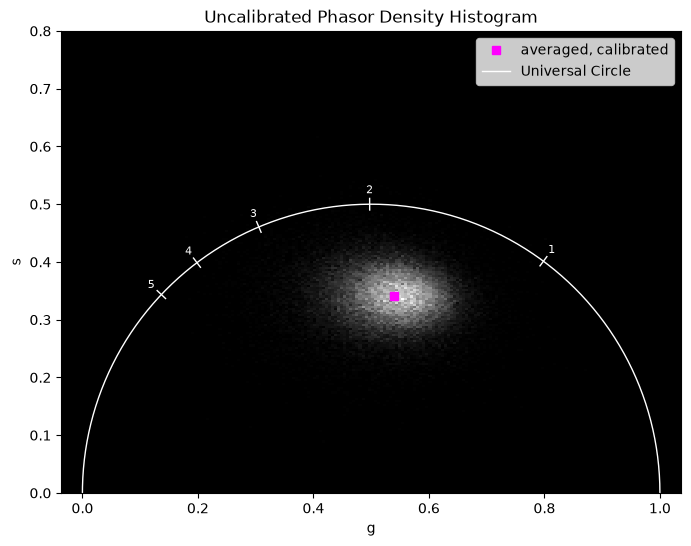

In [20]:
from tttrkit.analysis.phasor import smooth_phasor, average_phasor

phasor_smoothed = smooth_phasor(
    phasor = phasor,
    photon_count=photon_count_image,
    size = 3
)

phasor_averaged = average_phasor(
    phasor=phasor,
    photon_count=photon_count_image,

)

valid = valid = np.isfinite(phasor) & (photon_count_image > 0)


g_smooth = phasor_smoothed[valid].real
s_smooth = phasor_smoothed[valid].imag

H, xedges, yedges = np.histogram2d(g_smooth, s_smooth, bins=150)


fig, ax = plt.subplots(figsize=(8,6))

ax.imshow(H.T, origin='lower',
          extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
          cmap='gray', aspect='equal',interpolation="nearest")
ax.set_xlabel('g')
ax.set_ylabel('s')
ax.set_title('Uncalibrated Phasor Density Histogram')
ax.set_xlim((0,1))
ax.set_ylim((0,1))
ax.set_facecolor('black')

ax.plot(
    phasor_averaged.real,
    phasor_averaged.imag,
    color = 'magenta',
    linestyle='',
    marker = 's',
    label = 'averaged, calibrated',
)


draw_unitary_circle(ax, sync_rate=repetition_rate, tau_max = 5)

ax.legend()

# ax.plot(phasor_measured.real,phasor_measured.imag,"rs")
plt.show()
